# **Experimet 7 : Titanic rescue prediction using Decision Tree And  Random Forest**


## **Objective**

To develop a **Decision Tree classification model** that predicts whether a Titanic passenger survived or not, using passenger attributes (age, gender, class, fare, etc.). The goal is to build a transparent, interpretable model to capture relationships between features and survival, and to evaluate the model’s predictive performance.

## **Problem Overview**

The Titanic dataset is one of the canonical datasets for binary classification: given information about passengers (such as age, sex, passenger class, fare, number of siblings/spouses, number of parents/children aboard, and other derived features), the task is to predict whether a passenger survived (1) or died (0) in the shipwreck.

Challenges and considerations include:

* Missing values (e.g. for **Age**, **Cabin**)
* Categorical variables that need encoding (e.g. **Sex**, **Embarked**)
* Feature engineering to improve signal (e.g. combining siblings and parents into family size)
* Avoiding overfitting (Decision Trees can fit training data too well)
* Choosing tree hyperparameters (max depth, min samples split, etc.)
* Interpreting the learned tree (which features drive decisions)

Because Decision Trees are inherently interpretable, this approach also offers insight into which factors are most important in predicting survival.

## **Introduction**

In this notebook, the author applies a Decision Tree classifier to the Titanic dataset. The process includes exploratory data analysis, preprocessing (handling missing data and encoding categorical variables), feature engineering, training the decision tree, and evaluating its performance. Visualizations (such as feature importance plots) are used to interpret results. The notebook demonstrates how a classical machine learning model can be applied end-to-end to a real-world classification problem.

## **Stepwise Implementation**

Here is a typical pipeline, aligned with what is likely in that notebook:

1. **Import libraries**
   Import standard Python libraries and modules: `pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`, and scikit-learn tools (for splitting, modeling, metrics).

2. **Load dataset**
   Load the Titanic dataset (e.g. `train.csv`, `test.csv`) into DataFrames. Use `.shape`, `.info()`, `.head()`, and `.isnull().sum()` to get an overview.

3. **Exploratory Data Analysis (EDA)**

   * Investigate distributions of numeric features (Age, Fare)
   * Visualize counts of categorical features by survival (Gender, Passenger Class, Embarked)
   * Correlation heatmap among numeric features
   * Identify trends or patterns (e.g. survival by class, by sex, by fare ranges)

4. **Data cleaning / handling missing values**

   * Impute missing `Age` values (e.g., with median or by grouping by other features)
   * Fill missing `Embarked` entries
   * Handle missing `Cabin` (could drop or extract useful info like first letter)
   * Drop or transform features with too many missing values or low usefulness (e.g. Ticket, Name)

5. **Feature engineering**

   * Create **FamilySize** = `SibSp + Parch + 1`
   * Derive **IsAlone** (if FamilySize == 1)
   * Extract **Title** from the Name (e.g. Mr, Mrs, Miss)
   * Possibly bin continuous features (e.g. Age groups, Fare bins)

6. **Encode categorical variables**

   * Convert `Sex` to numeric (e.g. female = 0 or 1)
   * One-hot encode or dummy encode `Embarked`
   * Map `Title` or other derived categorical fields to numeric or dummy form

7. **Select features and target**

   * Define feature matrix **X** including the cleaned and engineered features
   * Define target **y** as survival (0/1)

8. **Split into training and validation sets**

   * Use `train_test_split()` (e.g. 70/30 or 80/20) with a random state for reproducibility

9. **Model instantiation & training**

   * Instantiate `DecisionTreeClassifier` with some hyperparameters (e.g. `max_depth`, `min_samples_split`)
   * Train the model on the training set with `.fit(X_train, y_train)`

10. **Prediction & evaluation**

    * Predict on the validation set (`.predict(X_valid)`)
    * Compute accuracy
    * Generate a confusion matrix and plot as a heatmap
    * Produce a classification report showing precision, recall, f1-score
    * Extract feature importances from the tree and plot them

11. **Hyperparameter tuning / pruning (if applied)**

    * Adjust tree parameters to reduce overfitting (e.g. reduce max depth, increase min samples leaf)
    * Possibly use cross-validation or grid search to find optimal parameters

12. **Final evaluation and interpretation**

    * Assess model generalization on held-out test data
    * Interpret which features the decision tree considered most important
    * Optionally visualize the decision tree (e.g. with `plot_tree`)


In [5]:
import pandas as pd
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.model_selection import train_test_split

#### **PART 1: Data Handling**

In [6]:
data=pd.read_csv("https://raw.githubusercontent.com/prashantkumarniraj/Machine-Learning/94cd54866ffbfa6e98c864ea1ccbe05d2b6941e7/Experiment7/titanic.csv")

In [7]:
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [8]:
#Using drop function to exclude collums I won't need. The parameter inplace true will change the table
data.drop(["PassengerId", "Name","SibSp","Parch","Ticket","Fare","Cabin","Embarked"], axis="columns",inplace=True)
data.head()

,Survived,Pclass,Sex,Age
0,0,3,male,22.0
1,1,1,female,38.0
2,1,3,female,26.0
3,1,1,female,35.0
4,0,3,male,35.0


In [9]:
# To define X I can simply drop the collumn I don't need, which is the Y
# Here I am not using the parameter inplace, thus it is automaticaly set as "False" and doesn't change the table
X = data.drop(["Survived"],axis="columns")
# For the variable Y I can simply select the column Survived
Y = data["Survived"] #Another way to declare: Y = data.Survived
Y

,Survived
0,0
1,1
2,1
3,1
4,0
...,...
886,0
887,1
888,0
889,1


In [10]:
#The next step: create a pattern
#Pattern: Male = 0 / Female = 1
#This method map will create synonims in a dictionary
X.Sex = X.Sex.map({"male":0,"female":1})
X.head()

,Pclass,Sex,Age
0,3,0,22.0
1,1,1,38.0
2,3,1,26.0
3,1,1,35.0
4,3,0,35.0


In [11]:
#Some filles with the ages are empy. Checkin out the first 10 lines
X.Age[0:10]

,Age
0,22.0
1,38.0
2,26.0
3,35.0
4,35.0
5,NaN
6,54.0
7,2.0
8,27.0
9,14.0


In [12]:
# To fix this, we will use method fillna(). Inside the brackets I'll put the information to replace, which will be the mean
X.Age = X.Age.fillna(X.Age.mean())
X.Age[0:10]
#Index 5 was empty and is now showing the mean (29.699118)

,Age
0,22.000000
1,38.000000
2,26.000000
3,35.000000
4,35.000000
5,29.699118
6,54.000000
7,2.000000
8,27.000000
9,14.000000


In [13]:
#Now want data to training (80%) and testing (20%)
#Sklearn has a method to automaticaly make this division"train_test_split"
#Parameters: X, Y, percentage. If I put one, the method will automaticaly calculate the other
train_test_split(X,Y,train_size = 0.8) # It is automaticaly setting 0.2 for testing
# The table will show X_training [712 rows x 3 columns], X_test [179 rows x 3 columns], Y_training[Length: 712, Y_test[Length: 179]

[     Pclass  Sex        Age
 493       1    0  71.000000
 699       3    0  42.000000
 343       2    0  25.000000
 643       3    0  29.699118
 544       1    0  50.000000
 ..      ...  ...        ...
 380       1    1  42.000000
 0         3    0  22.000000
 305       1    0   0.920000
 345       2    1  24.000000
 83        1    0  28.000000
 
 [712 rows x 3 columns],
      Pclass  Sex        Age
 830       3    1  15.000000
 870       3    0  26.000000
 531       3    0  29.699118
 639       3    0  29.699118
 644       3    1   0.750000
 ..      ...  ...        ...
 3         1    1  35.000000
 36        3    0  29.699118
 781       1    1  17.000000
 512       1    0  36.000000
 727       3    1  29.699118
 
 [179 rows x 3 columns],
 493    0
 699    0
 343    0
 643    1
 544    0
       ..
 380    1
 0      0
 305    1
 345    1
 83     0
 Name: Survived, Length: 712, dtype: int64,
 830    1
 870    0
 531    0
 639    0
 644    1
       ..
 3      1
 36     1
 781    1
 512  

In [14]:
# Now I create 4 variables to place each parameter
X_train,X_test,Y_train,Y_real=train_test_split(X,Y,train_size = 0.8)
#to see the lenght:
len(X_train)

712

In [15]:
len(X_test)

179

In [16]:
#Note that X_test is not in order. It presents it ramdomly to prevent model from becoming biased
X_test

,Pclass,Sex,Age
457,1,1,29.699118
192,3,1,19.000000
600,2,1,24.000000
84,2,1,17.000000
720,2,1,6.000000
...,...,...,...
444,3,0,29.699118
828,3,0,29.699118
224,1,0,38.000000
576,2,1,34.000000


## **Data Analysis**  
* **Decision Tree**
* **Random Forest**

## **1. Decision Tree**   

In [17]:
#If it is empty it will create it with as many levels it can. TO avoid this we put max_dep to determine how many levels we want
#The sext parameter will be the criteria. If I dont put it will use gini. If I wanted to use entropy I'd have to put it. I want to use gini, so I don't need to put it
model_dt = tree.DecisionTreeClassifier(max_depth=3)   #model with deph 3
model_dt

DecisionTreeClassifier(max_depth=3)

In [18]:
#Now the method fit will adjust data, trainning the model
model_dt.fit(X_train,Y_train)

DecisionTreeClassifier(max_depth=3)

In [19]:
#Using predict method to test the model
model_dt.predict(X_test) #always gets x and retuns y

array([1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 0])

In [20]:
#Storing the result in a variable
Y_pred_dt = model_dt.predict(X_test)
Y_pred_dt

array([1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 0])

In [21]:
#Dataframe to show Y real and Y predicted:
#Using a dictionary to separate columns
result = pd.DataFrame({"Survided REAL": Y_real, "Survived PREDICTION": Y_pred_dt})
result

,Survided REAL,Survived PREDICTION
457,1,1
192,1,1
600,1,1
84,1,1
720,1,1
...,...,...
444,1,0
828,1,0
224,1,0
576,1,1


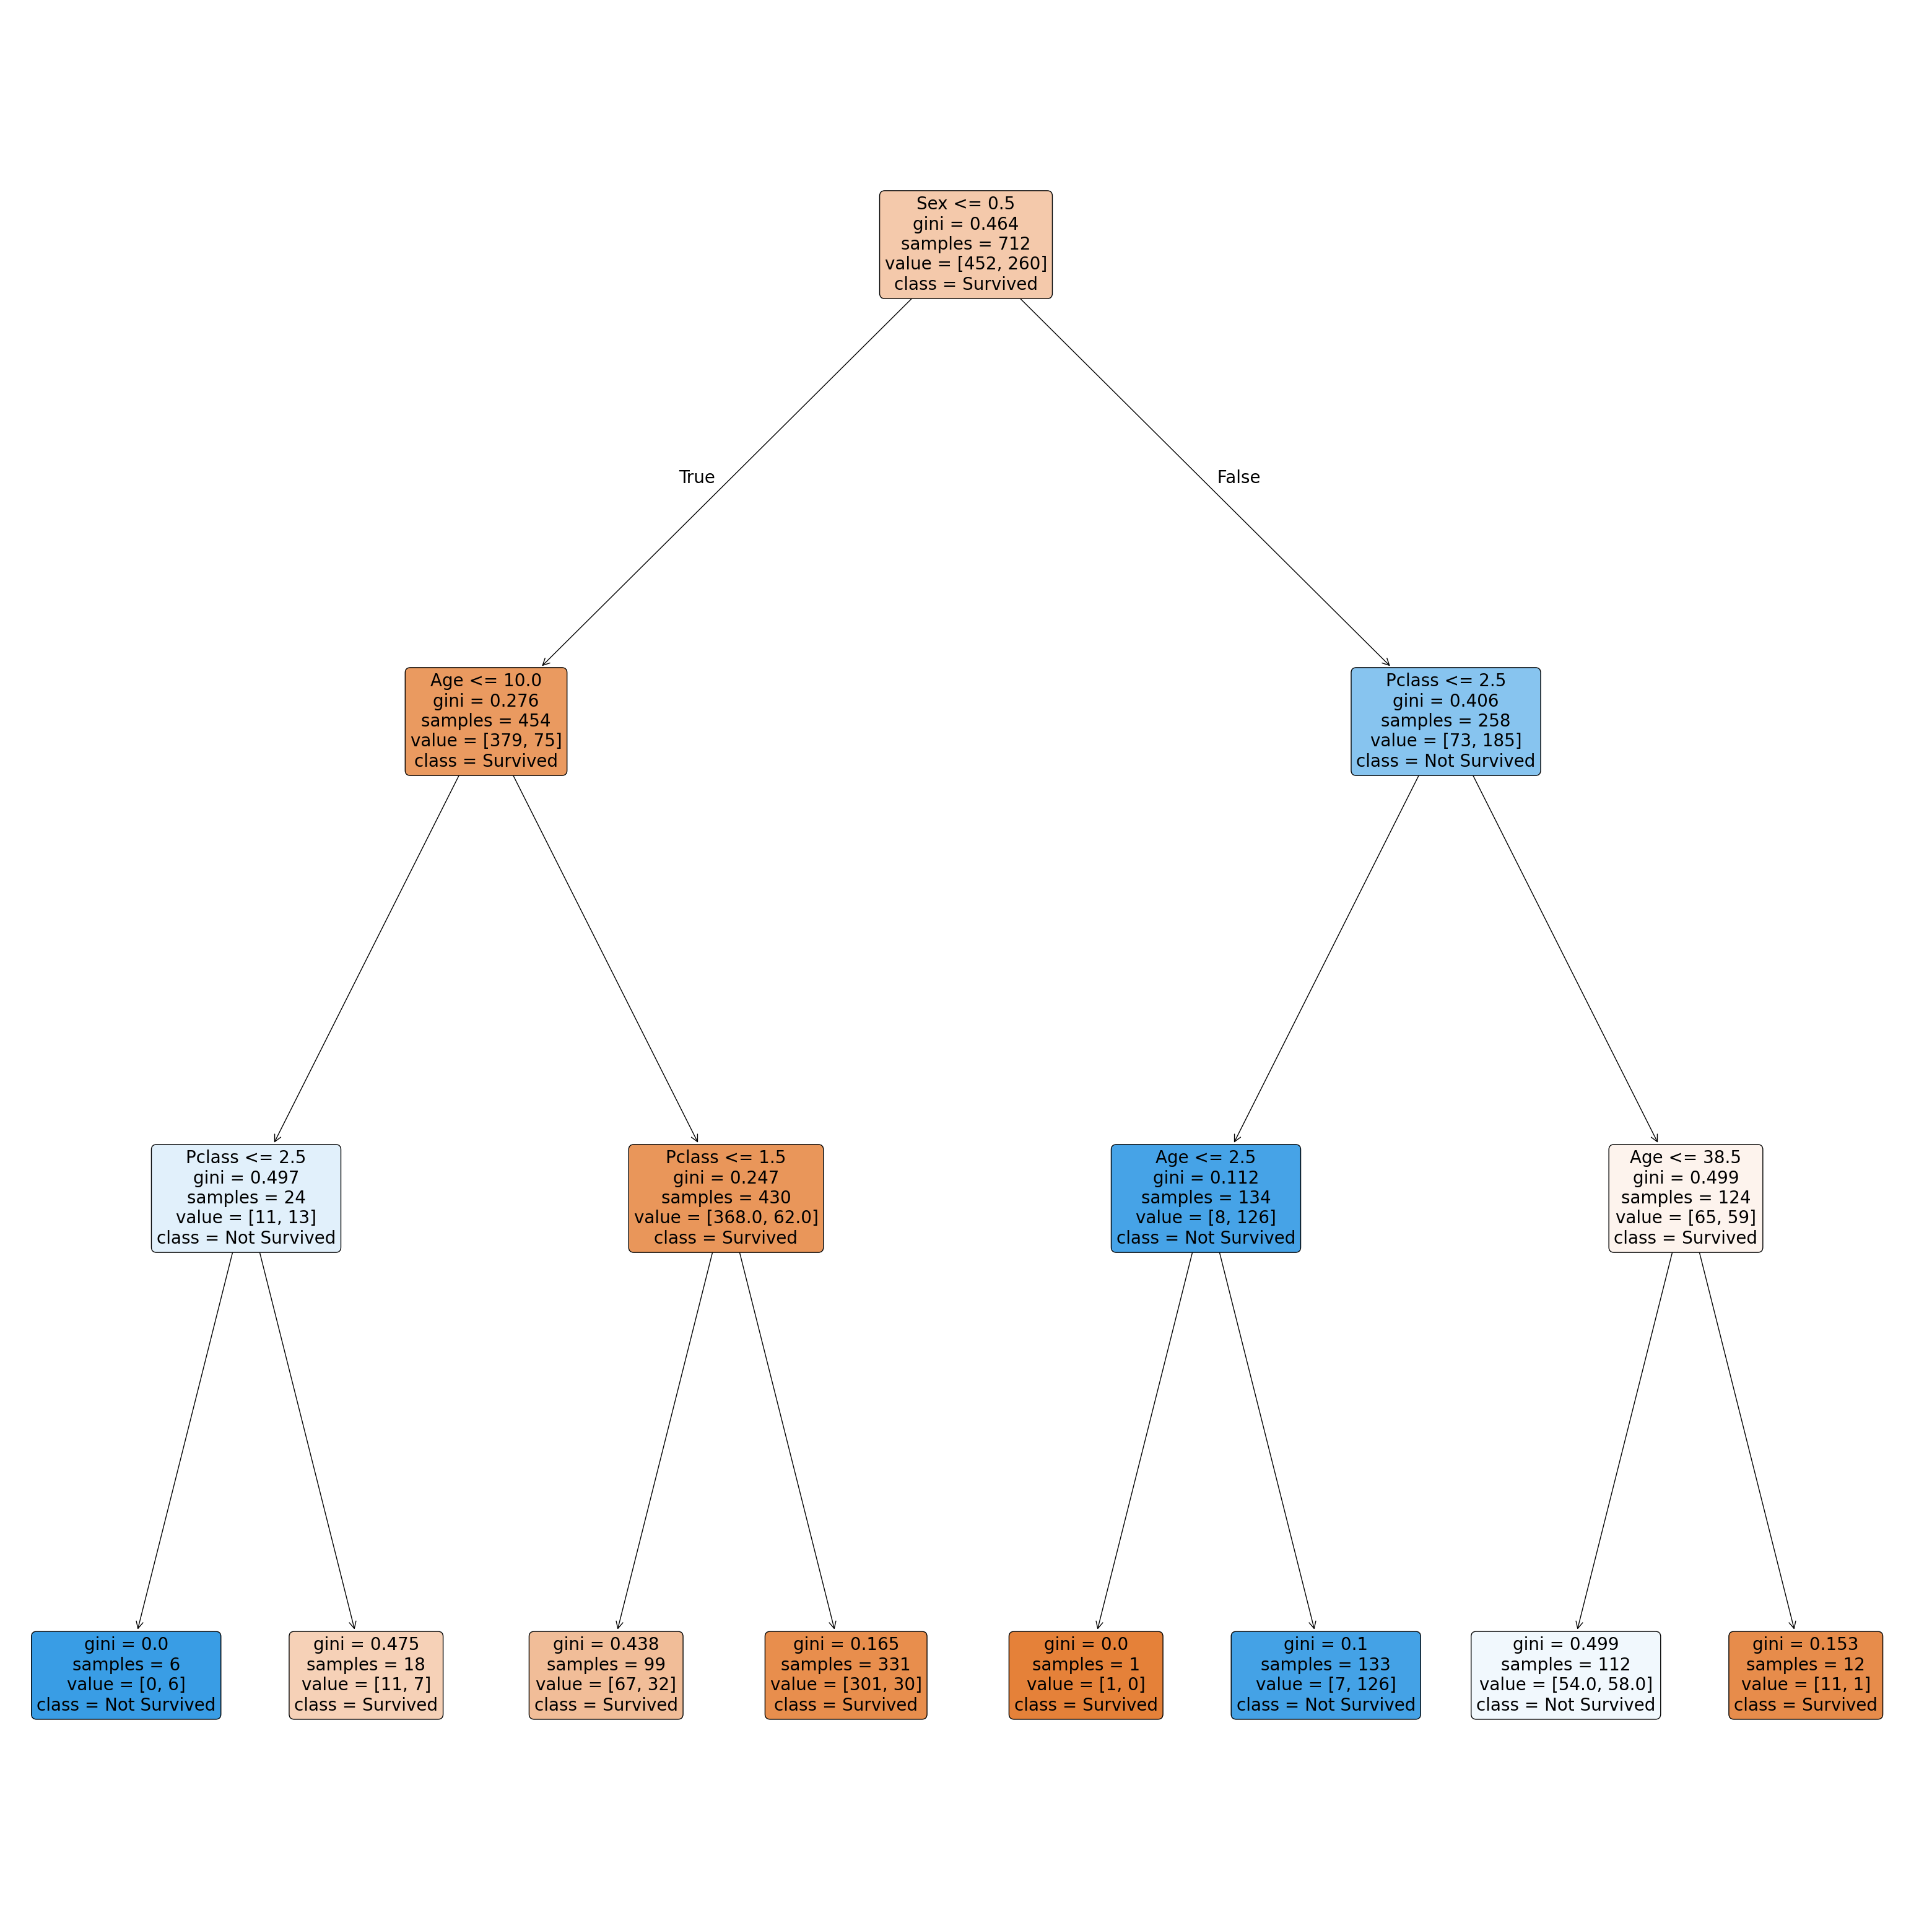

In [22]:
# Plotting the tree
plt.figure(figsize=(40,40))
graph_tree = plot_tree (model_dt,feature_names = ['Pclass','Sex','Age'],
                        class_names = ['Survived','Not Survived'],
                        filled=True,rounded=True,fontsize = 20)

 #### **Decision Tree - Performance Measurement**

#### **a) Accuracy**

In [23]:
# Accuracy = true negatives + true positives / true positives + false positives + true negatives + false negatives
accuracy_dt = model_dt.score(X_test,Y_real)
accuracy_dt

0.7877094972067039

In [24]:
# Here is another way to find the accuracy score
from sklearn import metrics
accuracy = metrics.accuracy_score(Y_real,Y_pred_dt)
accuracy

0.7877094972067039

#### **b) Precision**

In [25]:
# Precision = true positive / true positive + false positive
precision_dt = metrics.precision_score(Y_real,Y_pred_dt)
precision_dt

0.8666666666666667

#### **c) Recall**

In [26]:
# Recall = true positive / true positive + false negative
recall_dt = metrics.recall_score(Y_real,Y_pred_dt)
recall_dt

0.6341463414634146

#### **d) Confusion matrix**

In [27]:
import seaborn as sns
confusion_matrix_dt = metrics.confusion_matrix(Y_real,Y_pred_dt)
confusion_matrix_dt

array([[89,  8],
       [30, 52]])

<Axes: >

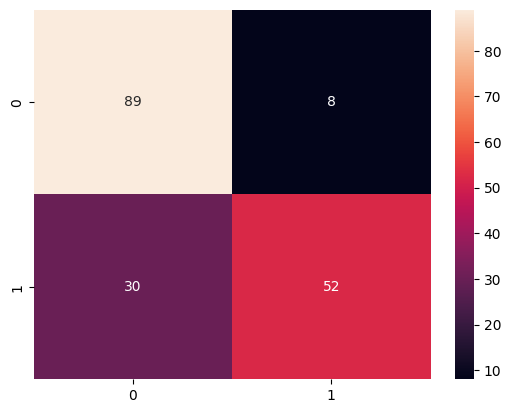

In [28]:
# 0,0: 53 => True Negative
# 0,1: 0  => False Positive
# 1,0: 23 => False Negative
# 1,1: 4  => True Positive
sns.heatmap(confusion_matrix_dt, annot=True)

#### **e) AUC - ROC Curve**

In [29]:
auc_dt = metrics.roc_auc_score(Y_real, Y_pred_dt) # as the documentation explain, the main parameters are: y_true and y_score
auc_dt

np.float64(0.7758360573296456)

#### **Decision Tree - k-Fold Cross-Validation**

Now using kfold, a model validation technique which is not using my pre-trained model


In [30]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

In [31]:
kf_dt = KFold(n_splits=5,shuffle=True)
cv_dt = cross_val_score(model_dt, X, Y, cv=kf_dt)
np.mean(cv_dt)

np.float64(0.8058439520431862)

## **2. Random Forest**  

In [32]:
from sklearn.ensemble import RandomForestClassifier

In [33]:
model_rf = RandomForestClassifier().fit(X_train,Y_train)

In [34]:
y_pred_forest = model_rf.predict(X_test)
y_pred_forest

array([1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 1, 0])

#### **Random Forest - Performance Measurement**

#### **a) Accuracy**

In [35]:
# Accuracy = true negatives + true positives / true positives + false positives + true negatives + false negatives
accuracy_forest = model_rf.score(X_test,Y_real)
accuracy_forest

0.7932960893854749

In [36]:
# Here is another way to find the accuracy score
accuracy_forest = metrics.accuracy_score(Y_real,y_pred_forest)
accuracy_forest

0.7932960893854749

#### **b) Precision**

In [37]:
# Precision = true positive / true positive + false positive
precision_forest = metrics.precision_score(Y_real,y_pred_forest)
precision_forest

0.8688524590163934

#### **c) Recall**

In [38]:
# Recall = true positive / true positive + false negative
recall_forest = metrics.recall_score(Y_real, y_pred_forest)
recall_forest

0.6463414634146342

#### **d) Confusion matrix**

In [39]:
cm_forest = metrics.confusion_matrix(Y_real,y_pred_forest)
cm_forest

array([[89,  8],
       [29, 53]])

<Axes: >

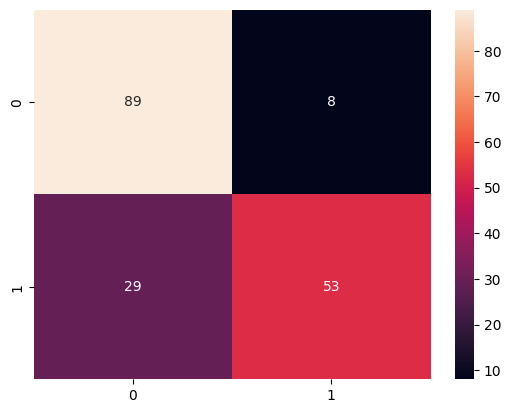

In [40]:
sns.heatmap(cm_forest, annot=True)

#### **e) AUC - Roc Curve**

In [41]:
auc_forest = metrics.roc_auc_score(Y_real, y_pred_forest) # as the documentation explain, the main parameters are: y_true and y_score
auc_forest

np.float64(0.7819336183052552)

#### **Random Forest - k-Fold Cross-Validation**
##### Now using kfold, a model validation technique which is not using my pre-trained model

In [42]:
kf_forest = KFold(n_splits=5,shuffle=True)

In [43]:
cv_forest = cross_val_score(model_rf, X, Y, cv=kf_forest)
np.mean(cv_forest)

np.float64(0.810281840436884)

#### **Valuation Analysis**

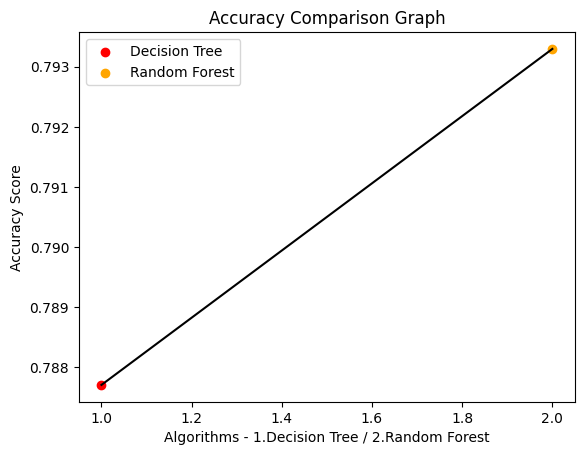

In [44]:
plt.title("Accuracy Comparison Graph")
plt.ylabel("Accuracy Score")
plt.xlabel("Algorithms - 1.Decision Tree / 2.Random Forest")
y = [accuracy_dt,accuracy_forest]
plt.plot([1,2],y, color = "black")
plt.scatter(1,accuracy_dt, marker="o", color="red", label="Decision Tree")
plt.scatter(2,accuracy_forest, marker="o", color = "orange",label = "Random Forest")
plt.legend()
plt.show()

## **Conclusion**

The Decision Tree classifier applied to the Titanic dataset offers a clear, interpretable model to predict survival, with the advantage of transparency (we can see which features and splits the model uses). While performance might not surpass more complex ensemble methods, it yields insights into feature importance and decision logic.

Key takeaways:

* Features such as **Sex**, **Pclass**, **Age**, **Title**, and **FamilySize / IsAlone** tend to play strong roles.
* Proper data cleaning, imputation, and feature engineering significantly improve model performance.
* Decision Trees are prone to overfitting; controlling depth and sample splits is necessary.
* The interpretability of decision trees is beneficial for understanding model behavior in a human-understandable way.
* For higher predictive performance, one might consider ensemble methods (Random Forests, Gradient Boosting) or hybrid approaches.
